In [1]:
# ============================================================
# CELL 1 — ENVIRONMENT CHECK
# ============================================================

import sys
import os

print("===== MARKETGUARD AI ENVIRONMENT =====")

print("Python version:")
print(sys.version)

print("\nPython executable:")
print(sys.executable)

print("\nWorking directory:")
print(os.getcwd())

print("\nFiles in current folder:")
for file in sorted(os.listdir(".")):
    print("   ", file)

===== MARKETGUARD AI ENVIRONMENT =====
Python version:
3.11.15 | packaged by Anaconda, Inc. | (main, Jun 11 2026, 15:12:53) [MSC v.1942 64 bit (AMD64)]

Python executable:
C:\Users\Evya\anaconda3\envs\marketguard\python.exe

Working directory:
C:\Users\Evya\MarketGuard_AI

Files in current folder:
    .ipynb_checkpoints
    A.csv
    AE.csv
    MarketGuard_AI_STGT.ipynb
    aapl_us_2025.csv
    marketguard_config.pkl
    marketguard_scaler.pkl
    marketguard_stgt_model.pth


In [2]:
# ============================================================
# CELL 2 — IMPORT LIBRARIES
# ============================================================

import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("===== LIBRARY CHECK =====")
print("NumPy   :", np.__version__)
print("Pandas  :", pd.__version__)
print("PyTorch :", torch.__version__)
print("Device  :", device)

# Important NumPy-PyTorch compatibility test
test_tensor = torch.tensor([1.0, 2.0, 3.0])
print("Tensor → NumPy:", test_tensor.numpy())

print("\nAll libraries working correctly.")

===== LIBRARY CHECK =====
NumPy   : 1.26.4
Pandas  : 3.0.5
PyTorch : 2.2.2
Device  : cpu
Tensor → NumPy: [1. 2. 3.]

All libraries working correctly.


In [3]:
# ============================================================
# CELL 3 — DATASET CONFIGURATION
# ============================================================

FILES = {
    "A": "A.csv",
    "AAPL": "aapl_us_2025.csv",
    "AE": "AE.csv"
}

REQUIRED_COLUMNS = [
    "Date",
    "Open",
    "High",
    "Low",
    "Close",
    "Volume"
]

print("===== DATASET CONFIGURATION =====")

for ticker, filename in FILES.items():
    print(f"{ticker:5s} -> {filename}")

print("\nRequired columns:")
print(REQUIRED_COLUMNS)

===== DATASET CONFIGURATION =====
A     -> A.csv
AAPL  -> aapl_us_2025.csv
AE    -> AE.csv

Required columns:
['Date', 'Open', 'High', 'Low', 'Close', 'Volume']


In [4]:
# ============================================================
# CELL 4 — LOAD DATASETS
# ============================================================

raw = {}

for ticker, filename in FILES.items():

    if not os.path.exists(filename):
        raise FileNotFoundError(
            f"\nERROR: {filename} was not found.\n"
            f"Current folder:\n{os.getcwd()}\n\n"
            "Make sure the CSV file is in the same folder "
            "as this notebook."
        )

    df = pd.read_csv(filename)

    # Check columns
    missing_columns = [
        col for col in REQUIRED_COLUMNS
        if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{filename} is missing columns: "
            f"{missing_columns}"
        )

    # Date processing
    df["Date"] = pd.to_datetime(
        df["Date"],
        errors="coerce"
    )

    # Numeric conversion
    numeric_columns = [
        "Open",
        "High",
        "Low",
        "Close",
        "Volume"
    ]

    for col in numeric_columns:
        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )

    # Clean
    df = (
        df.dropna(subset=["Date"])
          .sort_values("Date")
          .drop_duplicates("Date")
          .reset_index(drop=True)
    )

    raw[ticker] = df

    print(
        f"{ticker}: "
        f"{len(df):,} rows | "
        f"{df['Date'].min().date()} → "
        f"{df['Date'].max().date()}"
    )

print("\nAll datasets loaded successfully.")

A: 5,124 rows | 1999-11-18 → 2020-04-01
AAPL: 10,171 rows | 1984-09-07 → 2025-01-17
AE: 11,387 rows | 1975-02-07 → 2020-04-01

All datasets loaded successfully.


In [5]:
# ============================================================
# CELL 5 — DATASET INSPECTION
# ============================================================

for ticker, df in raw.items():

    print("\n" + "=" * 60)
    print(f"{ticker} DATASET")
    print("=" * 60)

    print("Shape:", df.shape)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nFirst 5 rows:")
    display(df.head())

    print("\nMissing values:")
    print(df.isnull().sum())


A DATASET
Shape: (5124, 7)

Columns:
['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']

First 5 rows:


,Date,Open,High,Low,Close,Adj Close,Volume
0,1999-11-18,32.546494,35.765381,28.612303,31.473534,27.068665,62546300
1,1999-11-19,30.713520,30.758226,28.478184,28.880543,24.838577,15234100
2,1999-11-22,29.551144,31.473534,28.657009,31.473534,27.068665,6577800
3,1999-11-23,30.400572,31.205294,28.612303,28.612303,24.607880,5975600
4,1999-11-24,28.701717,29.998211,28.612303,29.372318,25.261524,4843200



Missing values:
Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

AAPL DATASET
Shape: (10171, 6)

Columns:
['Date', 'Open', 'High', 'Low', 'Close', 'Volume']

First 5 rows:


,Date,Open,High,Low,Close,Volume
0,1984-09-07,0.099824,0.101049,0.098619,0.099824,9.859472e+07
1,1984-09-10,0.099824,0.100130,0.097424,0.099232,7.652559e+07
2,1984-09-11,0.100130,0.102846,0.100130,0.101049,1.804519e+08
3,1984-09-12,0.101049,0.101641,0.098007,0.098007,1.576401e+08
4,1984-09-13,0.103460,0.103754,0.103460,0.103460,2.455186e+08



Missing values:
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

AE DATASET
Shape: (11387, 7)

Columns:
['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']

First 5 rows:


,Date,Open,High,Low,Close,Adj Close,Volume
0,1975-02-07,0.0,5.5,4.0,4.0,2.530288,1500
1,1975-02-10,0.0,5.5,4.0,4.0,2.530288,100
2,1975-02-11,0.0,5.5,4.0,4.0,2.530288,0
3,1975-02-12,0.0,5.5,4.0,4.0,2.530288,0
4,1975-02-13,0.0,5.5,4.0,4.0,2.530288,500



Missing values:
Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64


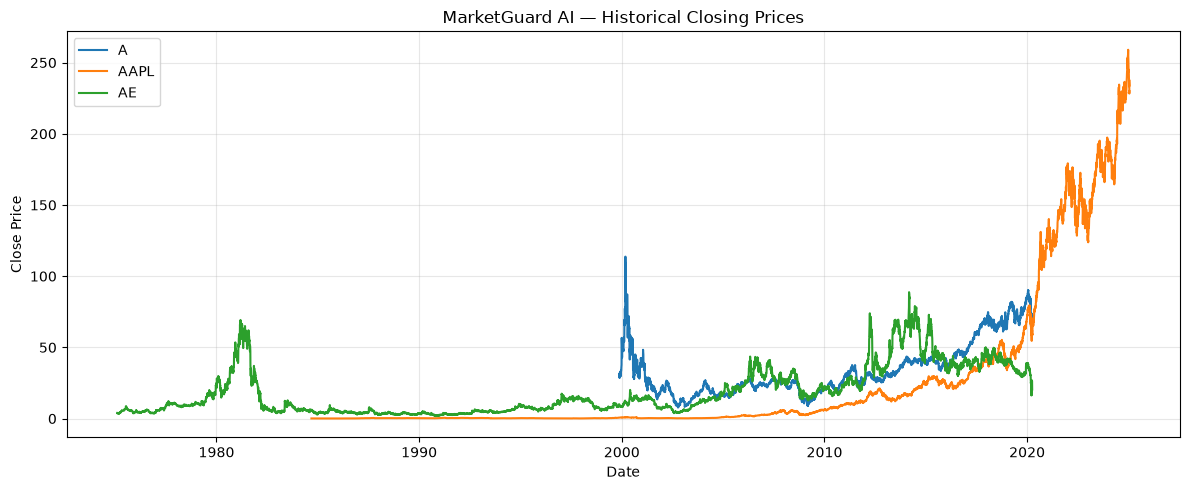

In [6]:
# ============================================================
# CELL 6 — CLOSING PRICE VISUALIZATION
# ============================================================

plt.figure(figsize=(12, 5))

for ticker, df in raw.items():

    plt.plot(
        df["Date"],
        df["Close"],
        label=ticker
    )

plt.title(
    "MarketGuard AI — Historical Closing Prices"
)

plt.xlabel("Date")
plt.ylabel("Close Price")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
# ============================================================
# CELL 7 — FEATURE ENGINEERING
# ============================================================

FEATURES = [
    "ret",
    "vol_chg",
    "sma5_gap",
    "sma20_gap",
    "rsi14",
    "volatility20",
    "volume_z20"
]

data = {}

for ticker, df0 in raw.items():

    d = df0.copy()

    # --------------------------------------------------------
    # 1. Daily return
    # --------------------------------------------------------
    d["ret"] = d["Close"].pct_change()

    # --------------------------------------------------------
    # 2. Volume change
    # --------------------------------------------------------
    d["vol_chg"] = d["Volume"].pct_change()

    # --------------------------------------------------------
    # 3. Moving averages
    # --------------------------------------------------------
    d["sma5"] = (
        d["Close"]
        .rolling(window=5)
        .mean()
    )

    d["sma20"] = (
        d["Close"]
        .rolling(window=20)
        .mean()
    )

    d["sma5_gap"] = (
        d["Close"] / d["sma5"]
    ) - 1

    d["sma20_gap"] = (
        d["Close"] / d["sma20"]
    ) - 1

    # --------------------------------------------------------
    # 4. RSI
    # --------------------------------------------------------
    delta = d["Close"].diff()

    gain = (
        delta.clip(lower=0)
        .rolling(window=14)
        .mean()
    )

    loss = (
        -delta.clip(upper=0)
        .rolling(window=14)
        .mean()
    )

    rs = gain / (loss + 1e-8)

    d["rsi14"] = (
        100 - (100 / (1 + rs))
    )

    # --------------------------------------------------------
    # 5. Rolling volatility
    # --------------------------------------------------------
    d["volatility20"] = (
        d["ret"]
        .rolling(window=20)
        .std()
    )

    # --------------------------------------------------------
    # 6. Volume Z-score
    # --------------------------------------------------------
    volume_mean = (
        d["Volume"]
        .rolling(window=20)
        .mean()
    )

    volume_std = (
        d["Volume"]
        .rolling(window=20)
        .std()
    )

    d["volume_z20"] = (
        (d["Volume"] - volume_mean)
        / (volume_std + 1e-8)
    )

    # --------------------------------------------------------
    # 7. Return Z-score
    #    Used for proxy suspicious-event generation
    # --------------------------------------------------------
    return_mean = (
        d["ret"]
        .rolling(window=20)
        .mean()
    )

    return_std = (
        d["ret"]
        .rolling(window=20)
        .std()
    )

    d["ret_z20"] = (
        (d["ret"] - return_mean)
        / (return_std + 1e-8)
    )

    # Replace invalid values
    d = d.replace(
        [np.inf, -np.inf],
        np.nan
    )

    d = d.set_index("Date")

    data[ticker] = d

print("Feature engineering completed.")

print("\nFeatures used by ST-GT:")
for feature in FEATURES:
    print("   ", feature)

print("\nAAPL sample:")
display(
    data["AAPL"][FEATURES].tail()
)

Feature engineering completed.

Features used by ST-GT:
    ret
    vol_chg
    sma5_gap
    sma20_gap
    rsi14
    volatility20
    volume_z20

AAPL sample:


,ret,vol_chg,sma5_gap,sma20_gap,rsi14,volatility20,volume_z20
Date,,,,,,,
2025-01-13,-0.010344,-0.195754,-0.024277,-0.057122,29.808449,0.012822,0.036875
2025-01-14,-0.004778,-0.205426,-0.019370,-0.058848,19.287576,0.012676,-0.377141
2025-01-15,0.019676,0.010059,0.003586,-0.038340,27.308294,0.013639,-0.377283
2025-01-16,-0.040400,0.801544,-0.025080,-0.072922,16.748112,0.015699,0.831792
2025-01-17,0.007535,-0.045580,-0.011935,-0.061457,18.379791,0.015601,0.663180


In [8]:
# ============================================================
# CELL 8 — ALIGN STOCKS ON COMMON DATES
# ============================================================

TICKERS = list(FILES.keys())

common_dates = data[TICKERS[0]].index

for ticker in TICKERS[1:]:
    common_dates = common_dates.intersection(
        data[ticker].index
    )

common_dates = common_dates.sort_values()

print("Stocks:", TICKERS)
print("Common dates:", len(common_dates))

print(
    "Common date range:",
    common_dates.min().date(),
    "→",
    common_dates.max().date()
)

N = len(TICKERS)
FNUM = len(FEATURES)

print("\nNumber of stocks:", N)
print("Number of features:", FNUM)

Stocks: ['A', 'AAPL', 'AE']
Common dates: 5124
Common date range: 1999-11-18 → 2020-04-01

Number of stocks: 3
Number of features: 7


In [9]:
# ============================================================
# CELL 9 — CREATE INPUT FEATURES AND PROXY TARGET
# ============================================================

# ------------------------------------------------------------
# Feature tensor
# Shape:
# (time, stocks, features)
# ------------------------------------------------------------

X_all = np.stack(
    [
        data[t]
        .loc[common_dates, FEATURES]
        .values
        for t in TICKERS
    ],
    axis=1
)

# ------------------------------------------------------------
# Return anomaly
# ------------------------------------------------------------

ret_z_all = np.stack(
    [
        data[t]
        .loc[common_dates, "ret_z20"]
        .values
        for t in TICKERS
    ],
    axis=1
)

# ------------------------------------------------------------
# Volume anomaly
# ------------------------------------------------------------

vol_z_all = np.stack(
    [
        data[t]
        .loc[common_dates, "volume_z20"]
        .values
        for t in TICKERS
    ],
    axis=1
)

# ------------------------------------------------------------
# Proxy suspicious-event target
#
# 1 = unusual next-day behaviour
# 0 = normal behaviour
#
# Condition:
# absolute return Z-score > 3
# OR
# volume Z-score > 3
# ------------------------------------------------------------

Y_all = np.zeros(
    (len(common_dates), N),
    dtype=np.float32
)

Y_all[:-1] = (
    (np.abs(ret_z_all[1:]) > 3)
    |
    (vol_z_all[1:] > 3)
).astype(np.float32)

# ------------------------------------------------------------
# Remove invalid rows
# ------------------------------------------------------------

valid = np.isfinite(X_all).all(axis=(1, 2))

valid &= np.isfinite(Y_all).all(axis=1)

# Last row has no next-day target
valid[-1] = False

X_all = X_all[valid]
Y_all = Y_all[valid]
DATES = common_dates[valid]

print("===== INPUT / TARGET INFORMATION =====")

print("X shape:", X_all.shape)
print("Y shape:", Y_all.shape)

print(
    "Interpretation:",
    "(time, stocks, features)"
)

print(
    "\nProxy suspicious-event rate:",
    round(Y_all.mean() * 100, 2),
    "%"
)

print(
    "Final date range:",
    DATES.min().date(),
    "→",
    DATES.max().date()
)

===== INPUT / TARGET INFORMATION =====
X shape: (5025, 3, 7)
Y shape: (5025, 3)
Interpretation: (time, stocks, features)

Proxy suspicious-event rate: 2.24 %
Final date range: 1999-12-17 → 2020-03-31


In [10]:
# ============================================================
# CELL 10 — CHRONOLOGICAL DATA SPLIT
# ============================================================

WINDOW = 20

n = len(X_all)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

print("===== CHRONOLOGICAL SPLIT =====")

print(
    "Training:",
    DATES[0].date(),
    "→",
    DATES[train_end - 1].date()
)

print(
    "Validation:",
    DATES[train_end].date(),
    "→",
    DATES[val_end - 1].date()
)

print(
    "Testing:",
    DATES[val_end].date(),
    "→",
    DATES[-1].date()
)

print("\nWindow length:", WINDOW)

===== CHRONOLOGICAL SPLIT =====
Training: 1999-12-17 → 2014-04-03
Validation: 2014-04-04 → 2017-03-31
Testing: 2017-04-03 → 2020-03-31

Window length: 20


In [11]:
# ============================================================
# CELL 11 — FEATURE SCALING
# ============================================================

scaler = StandardScaler()

# Fit ONLY on training data
scaler.fit(
    X_all[:train_end]
    .reshape(-1, FNUM)
)

# Transform all data
X_scaled = scaler.transform(
    X_all.reshape(-1, FNUM)
).reshape(
    n,
    N,
    FNUM
)

print("Feature scaling completed.")

print(
    "Scaler was fitted only on training data."
)

Feature scaling completed.
Scaler was fitted only on training data.


In [12]:
# ============================================================
# CELL 12 — DYNAMIC GRAPH CONSTRUCTION
# ============================================================

def build_dynamic_adjacency(
    return_window,
    top_k=1
):
    """
    Build a stock relationship graph using
    absolute return correlation.

    Input:
        return_window:
            shape = (time_window, stocks)

    Output:
        adjacency matrix:
            shape = (stocks, stocks)
    """

    correlation = np.corrcoef(
        return_window.T
    )

    correlation = np.nan_to_num(
        correlation,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    # Self connections
    adjacency = np.eye(
        N,
        dtype=np.float32
    )

    for i in range(N):

        ranking = np.argsort(
            -np.abs(correlation[i])
        )

        neighbours = [
            j for j in ranking
            if j != i
        ][:top_k]

        for j in neighbours:
            adjacency[i, j] = 1.0

    # Symmetric graph
    adjacency = np.maximum(
        adjacency,
        adjacency.T
    )

    return adjacency.astype(
        np.float32
    )


print("Dynamic graph function created.")

Dynamic graph function created.


In [13]:
# ============================================================
# CELL 13 — CREATE TEMPORAL WINDOWS + GRAPHS
# ============================================================

def make_sequences(
    start,
    end
):

    xs = []
    ys = []
    adjs = []
    dates_out = []

    first = max(
        WINDOW - 1,
        start
    )

    for i in range(first, end):

        # ----------------------------------------------------
        # 20-day feature window
        # ----------------------------------------------------
        x = X_scaled[
            i - WINDOW + 1 : i + 1
        ].astype(np.float32)

        # ----------------------------------------------------
        # Target for current date
        # ----------------------------------------------------
        y = Y_all[i].astype(
            np.float32
        )

        # ----------------------------------------------------
        # Returns used to create dynamic graph
        # ----------------------------------------------------
        return_window = X_all[
            i - WINDOW + 1 : i + 1,
            :,
            0
        ]

        # ----------------------------------------------------
        # Dynamic adjacency
        # ----------------------------------------------------
        adjacency = build_dynamic_adjacency(
            return_window,
            top_k=1
        )

        xs.append(x)
        ys.append(y)
        adjs.append(adjacency)
        dates_out.append(DATES[i])

    return (
        np.stack(xs),
        np.stack(ys),
        np.stack(adjs),
        np.array(dates_out)
    )


X_train, y_train, A_train, D_train = make_sequences(
    0,
    train_end
)

X_val, y_val, A_val, D_val = make_sequences(
    train_end,
    val_end
)

X_test, y_test, A_test, D_test = make_sequences(
    val_end,
    n
)

print("===== SEQUENCE SHAPES =====")

print(
    "Training   :",
    X_train.shape,
    y_train.shape,
    A_train.shape
)

print(
    "Validation :",
    X_val.shape,
    y_val.shape,
    A_val.shape
)

print(
    "Testing    :",
    X_test.shape,
    y_test.shape,
    A_test.shape
)

===== SEQUENCE SHAPES =====
Training   : (3498, 20, 3, 7) (3498, 3) (3498, 3, 3)
Validation : (754, 20, 3, 7) (754, 3) (754, 3, 3)
Testing    : (754, 20, 3, 7) (754, 3) (754, 3, 3)


===== RETURN CORRELATION MATRIX =====


,A,AAPL,AE
A,1.00,0.10,0.48
AAPL,0.10,1.00,0.41
AE,0.48,0.41,1.00



===== DYNAMIC ADJACENCY MATRIX =====


,A,AAPL,AE
A,1.0,0.0,1.0
AAPL,0.0,1.0,1.0
AE,1.0,1.0,1.0


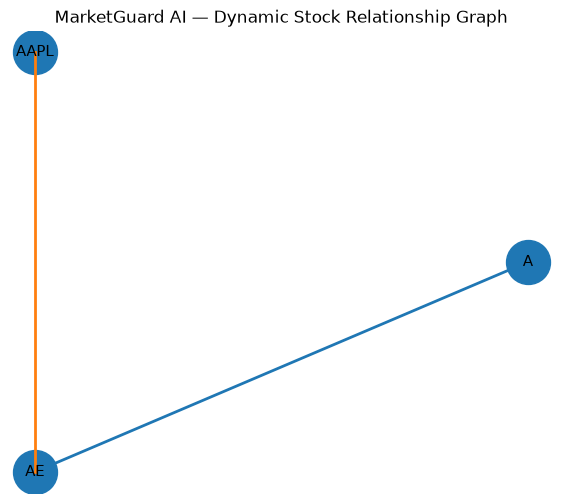

In [14]:
# ============================================================
# CELL 14 — VISUALIZE DYNAMIC STOCK GRAPH
# ============================================================

example_corr = np.corrcoef(
    X_all[
        train_end - WINDOW : train_end,
        :,
        0
    ].T
)

print("===== RETURN CORRELATION MATRIX =====")

display(
    pd.DataFrame(
        example_corr,
        index=TICKERS,
        columns=TICKERS
    ).round(2)
)

adj = A_train[-1]

print("\n===== DYNAMIC ADJACENCY MATRIX =====")

display(
    pd.DataFrame(
        adj,
        index=TICKERS,
        columns=TICKERS
    )
)

# ------------------------------------------------------------
# Draw graph
# ------------------------------------------------------------

plt.figure(figsize=(7, 6))

angles = np.linspace(
    0,
    2 * np.pi,
    N,
    endpoint=False
)

positions = np.c_[
    np.cos(angles),
    np.sin(angles)
]

# Edges
for i in range(N):

    for j in range(i + 1, N):

        if adj[i, j] > 0:

            plt.plot(
                [
                    positions[i, 0],
                    positions[j, 0]
                ],
                [
                    positions[i, 1],
                    positions[j, 1]
                ],
                linewidth=2
            )

# Nodes
plt.scatter(
    positions[:, 0],
    positions[:, 1],
    s=1000
)

# Labels
for i, ticker in enumerate(TICKERS):

    plt.text(
        positions[i, 0],
        positions[i, 1],
        ticker,
        ha="center",
        va="center",
        fontsize=11
    )

plt.title(
    "MarketGuard AI — Dynamic Stock Relationship Graph"
)

plt.axis("off")
plt.show()

In [15]:
# ============================================================
# CELL 15 — GRAPH ATTENTION LAYER
# ============================================================

class GATLayer(nn.Module):

    def __init__(
        self,
        in_dim,
        out_dim
    ):

        super().__init__()

        self.W = nn.Linear(
            in_dim,
            out_dim,
            bias=False
        )

        self.a_src = nn.Parameter(
            torch.empty(out_dim)
        )

        self.a_dst = nn.Parameter(
            torch.empty(out_dim)
        )

        nn.init.xavier_uniform_(
            self.W.weight
        )

        nn.init.uniform_(
            self.a_src,
            -0.1,
            0.1
        )

        nn.init.uniform_(
            self.a_dst,
            -0.1,
            0.1
        )

    def forward(
        self,
        x,
        adjacency
    ):
        """
        x:
            B × T × N × D

        adjacency:
            B × N × N
        """

        # Linear projection
        h = self.W(x)

        # Source attention
        source_score = (
            h * self.a_src
        ).sum(
            dim=-1,
            keepdim=True
        )

        # Destination attention
        destination_score = (
            h * self.a_dst
        ).sum(
            dim=-1,
            keepdim=True
        ).transpose(
            2,
            3
        )

        # Attention coefficients
        e = F.leaky_relu(
            source_score + destination_score,
            negative_slope=0.2
        )

        # Apply graph mask
        mask = (
            adjacency[:, None, :, :] > 0
        )

        e = e.masked_fill(
            ~mask,
            -1e9
        )

        # Normalize
        attention = torch.softmax(
            e,
            dim=-1
        )

        # Aggregate neighbours
        output = torch.matmul(
            attention,
            h
        )

        return output


print("GAT layer defined successfully.")

GAT layer defined successfully.


In [16]:
# ============================================================
# CELL 16 — SPATIO-TEMPORAL GRAPH TRANSFORMER
# ============================================================

class STGT(nn.Module):

    def __init__(
        self,
        n_features,
        d_model=32,
        n_heads=4,
        n_layers=2
    ):

        super().__init__()

        # ----------------------------------------------------
        # Feature projection
        # ----------------------------------------------------
        self.input_projection = nn.Linear(
            n_features,
            d_model
        )

        # ----------------------------------------------------
        # Spatial graph attention
        # ----------------------------------------------------
        self.gat = GATLayer(
            d_model,
            d_model
        )

        # ----------------------------------------------------
        # Temporal Transformer
        # ----------------------------------------------------
        encoder_layer = (
            nn.TransformerEncoderLayer(
                d_model=d_model,
                nhead=n_heads,
                dim_feedforward=d_model * 2,
                dropout=0.1,
                batch_first=True,
                activation="gelu"
            )
        )

        self.transformer = (
            nn.TransformerEncoder(
                encoder_layer,
                num_layers=n_layers
            )
        )

        # ----------------------------------------------------
        # Normalization
        # ----------------------------------------------------
        self.norm = nn.LayerNorm(
            d_model
        )

        # ----------------------------------------------------
        # Stock-wise classifier
        # ----------------------------------------------------
        self.classifier = nn.Linear(
            d_model,
            1
        )

    def forward(
        self,
        x,
        adjacency
    ):

        # x:
        # B × T × N × F

        # ----------------------------------------------------
        # Feature projection
        # ----------------------------------------------------
        h = torch.relu(
            self.input_projection(x)
        )

        # ----------------------------------------------------
        # Spatial relationship learning
        # ----------------------------------------------------
        h = torch.relu(
            self.gat(
                h,
                adjacency
            )
        )

        # Shape
        B, T, N, D = h.shape

        # ----------------------------------------------------
        # Rearrange for temporal Transformer
        # Each stock gets its own temporal sequence.
        # ----------------------------------------------------
        h = h.permute(
            0, 2, 1, 3
        )

        h = h.reshape(
            B * N,
            T,
            D
        )

        # ----------------------------------------------------
        # Temporal learning
        # ----------------------------------------------------
        h = self.transformer(h)

        # Take final timestep
        h = h[:, -1, :]

        # Restore stock dimension
        h = h.reshape(
            B,
            N,
            D
        )

        # Normalization
        h = self.norm(h)

        # Stock-wise prediction
        logits = self.classifier(h)

        return logits.squeeze(-1)


# Create model
model = STGT(
    n_features=FNUM,
    d_model=32,
    n_heads=4,
    n_layers=2
).to(device)

print(model)

print("\nModel device:", device)

STGT(
  (input_projection): Linear(in_features=7, out_features=32, bias=True)
  (gat): GATLayer(
    (W): Linear(in_features=32, out_features=32, bias=False)
  )
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
        )
        (linear1): Linear(in_features=32, out_features=64, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=64, out_features=32, bias=True)
        (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (norm): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
  (classifier): Linear(in_features=32, out_features=1, bias=True)
)

Model

In [17]:
# ============================================================
# CELL 17 — PYTORCH DATA LOADERS
# ============================================================

def make_loader(
    X,
    Y,
    A,
    shuffle=False,
    batch_size=64
):

    dataset = TensorDataset(

        torch.tensor(
            X,
            dtype=torch.float32
        ),

        torch.tensor(
            Y,
            dtype=torch.float32
        ),

        torch.tensor(
            A,
            dtype=torch.float32
        )
    )

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle
    )


train_loader = make_loader(
    X_train,
    y_train,
    A_train,
    shuffle=True
)

val_loader = make_loader(
    X_val,
    y_val,
    A_val,
    shuffle=False
)

test_loader = make_loader(
    X_test,
    y_test,
    A_test,
    shuffle=False
)

print("DataLoaders created.")

print(
    "Training batches:",
    len(train_loader)
)

print(
    "Validation batches:",
    len(val_loader)
)

print(
    "Testing batches:",
    len(test_loader)
)

DataLoaders created.
Training batches: 55
Validation batches: 12
Testing batches: 12


In [18]:
# ============================================================
# CELL 18 — CLASS IMBALANCE HANDLING
# ============================================================

positive = float(
    y_train.sum()
)

negative = float(
    y_train.size - y_train.sum()
)

positive_rate = (
    positive /
    (positive + negative)
)

print("Positive samples :", int(positive))
print("Negative samples :", int(negative))
print(
    "Positive rate    :",
    round(positive_rate * 100, 2),
    "%"
)

# Weight positive class more heavily
pos_weight_value = (
    negative /
    max(positive, 1.0)
)

pos_weight = torch.tensor(
    pos_weight_value,
    dtype=torch.float32,
    device=device
)

print(
    "Positive class weight:",
    round(pos_weight_value, 2)
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

print("\nLoss function and optimizer ready.")

Positive samples : 234
Negative samples : 10260
Positive rate    : 2.23 %
Positive class weight: 43.85

Loss function and optimizer ready.


In [19]:
# ============================================================
# CELL 19 — MODEL TRAINING
# ============================================================

def run_epoch(
    loader,
    training=False
):

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0

    for xb, yb, ab in loader:

        xb = xb.to(device)
        yb = yb.to(device)
        ab = ab.to(device)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):

            logits = model(
                xb,
                ab
            )

            loss = criterion(
                logits,
                yb
            )

        if training:

            loss.backward()

            # Prevent exploding gradients
            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

        total_loss += (
            loss.item() *
            xb.size(0)
        )

    return (
        total_loss /
        len(loader.dataset)
    )


# ------------------------------------------------------------
# First successful run
# ------------------------------------------------------------

EPOCHS = 5

history = {
    "train_loss": [],
    "val_loss": []
}

print("===== TRAINING ST-GT =====")

for epoch in range(
    1,
    EPOCHS + 1
):

    train_loss = run_epoch(
        train_loader,
        training=True
    )

    val_loss = run_epoch(
        val_loader,
        training=False
    )

    history["train_loss"].append(
        train_loss
    )

    history["val_loss"].append(
        val_loss
    )

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )

print("\nTraining completed successfully.")

===== TRAINING ST-GT =====
Epoch 1/5 | Train Loss: 1.3554 | Validation Loss: 1.2309
Epoch 2/5 | Train Loss: 1.2984 | Validation Loss: 1.2311
Epoch 3/5 | Train Loss: 1.2909 | Validation Loss: 1.2094
Epoch 4/5 | Train Loss: 1.2712 | Validation Loss: 1.2122
Epoch 5/5 | Train Loss: 1.2573 | Validation Loss: 1.2892

Training completed successfully.


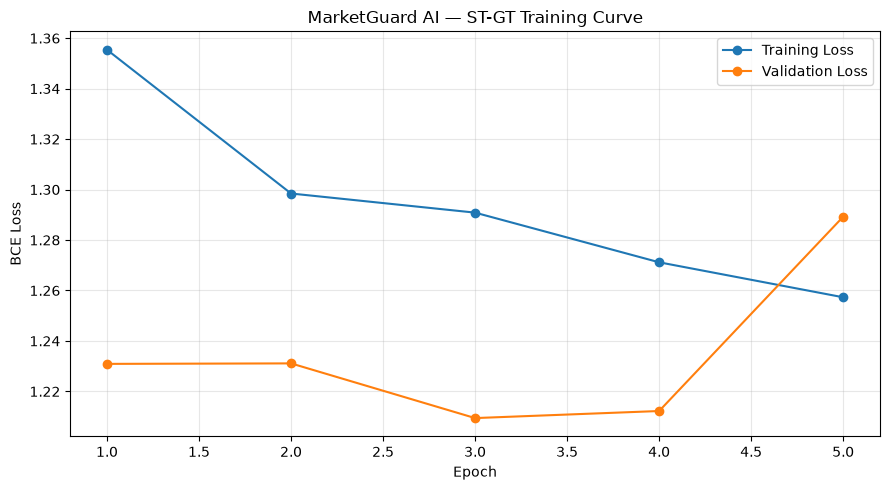

In [20]:
# ============================================================
# CELL 20 — TRAINING CURVE
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, EPOCHS + 1),
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, EPOCHS + 1),
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title(
    "MarketGuard AI — ST-GT Training Curve"
)

plt.xlabel("Epoch")
plt.ylabel("BCE Loss")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [21]:
# ============================================================
# CELL 21 — TEST PREDICTIONS
# ============================================================

model.eval()

all_probs = []
all_true = []

with torch.no_grad():

    for xb, yb, ab in test_loader:

        xb = xb.to(device)
        ab = ab.to(device)

        logits = model(
            xb,
            ab
        )

        probabilities = torch.sigmoid(
            logits
        ).cpu().numpy()

        all_probs.append(
            probabilities
        )

        all_true.append(
            yb.numpy()
        )


probs = np.concatenate(
    all_probs,
    axis=0
)

true = np.concatenate(
    all_true,
    axis=0
)

print("Probability shape:")
print(probs.shape)

print("\nPrediction generation completed.")

Probability shape:
(754, 3)

Prediction generation completed.


In [22]:
# ============================================================
# CELL 22 — VALIDATION THRESHOLD SELECTION
# ============================================================

model.eval()

val_probs = []
val_true = []

with torch.no_grad():

    for xb, yb, ab in val_loader:

        logits = model(
            xb.to(device),
            ab.to(device)
        )

        p = torch.sigmoid(
            logits
        ).cpu().numpy()

        val_probs.append(p)
        val_true.append(
            yb.numpy()
        )

val_probs = np.concatenate(
    val_probs
).ravel()

val_true = np.concatenate(
    val_true
).ravel()


thresholds = np.arange(
    0.10,
    0.91,
    0.05
)

best_threshold = 0.50
best_f1 = -1

for threshold in thresholds:

    val_pred = (
        val_probs >= threshold
    ).astype(int)

    score = f1_score(
        val_true,
        val_pred,
        zero_division=0
    )

    if score > best_f1:

        best_f1 = score
        best_threshold = threshold


print(
    "Best validation threshold:",
    round(best_threshold, 2)
)

print(
    "Validation F1:",
    round(best_f1, 4)
)

Best validation threshold: 0.7
Validation F1: 0.0716


In [23]:
# ============================================================
# CELL 23 — FINAL TEST EVALUATION
# ============================================================

y_true_flat = true.ravel()
p_flat = probs.ravel()

# Use validation-selected threshold
y_pred_flat = (
    p_flat >= best_threshold
).astype(int)


accuracy = accuracy_score(
    y_true_flat,
    y_pred_flat
)

precision = precision_score(
    y_true_flat,
    y_pred_flat,
    zero_division=0
)

recall = recall_score(
    y_true_flat,
    y_pred_flat,
    zero_division=0
)

f1 = f1_score(
    y_true_flat,
    y_pred_flat,
    zero_division=0
)

auc = roc_auc_score(
    y_true_flat,
    p_flat
)


print("=" * 50)
print("        MARKETGUARD AI — ST-GT RESULTS")
print("=" * 50)

print(
    f"Accuracy : {accuracy:.4f}"
)

print(
    f"Precision: {precision:.4f}"
)

print(
    f"Recall   : {recall:.4f}"
)

print(
    f"F1-score : {f1:.4f}"
)

print(
    f"ROC-AUC  : {auc:.4f}"
)

print("=" * 50)

        MARKETGUARD AI — ST-GT RESULTS
Accuracy : 0.7653
Precision: 0.0495
Recall   : 0.4483
F1-score : 0.0892
ROC-AUC  : 0.6589


Confusion Matrix:
[[1705  499]
 [  32   26]]


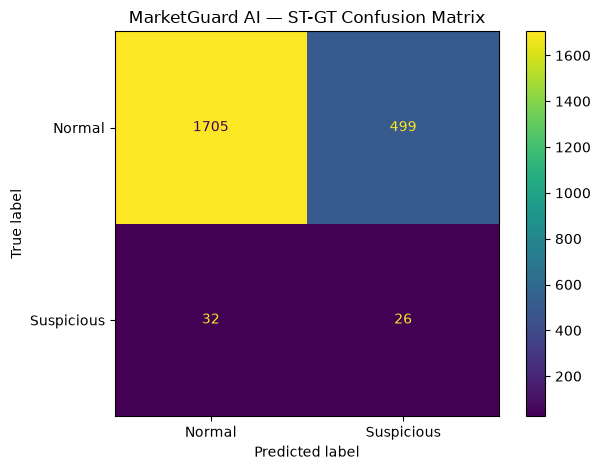

In [24]:
# ============================================================
# CELL 24 — CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true_flat,
    y_pred_flat
)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Normal",
        "Suspicious"
    ]
)

disp.plot()

plt.title(
    "MarketGuard AI — ST-GT Confusion Matrix"
)

plt.tight_layout()
plt.show()

In [25]:
# ============================================================
# CELL 25 — FINAL MARKETGUARD AI RISK OUTPUT
# ============================================================

# Last test window
last_probabilities = probs[-1]

risk_scores = (
    last_probabilities * 100
)


def risk_level(score):

    if score >= 70:
        return "HIGH"

    elif score >= 40:
        return "MEDIUM"

    else:
        return "LOW"


result = pd.DataFrame({

    "Stock": TICKERS,

    "Risk Score": np.round(
        risk_scores,
        2
    ),

    "Risk Level": [
        risk_level(score)
        for score in risk_scores
    ],

    "Model": [
        "ST-GT"
        for _ in TICKERS
    ]
})


print("=" * 60)
print("       MARKETGUARD AI — LATEST RISK OUTPUT")
print("=" * 60)

display(result)


print("\n===== INTERPRETATION =====")

for _, row in result.iterrows():

    print(
        f"{row['Stock']}: "
        f"{row['Risk Score']:.2f}/100 "
        f"→ {row['Risk Level']}"
    )


print("\nResearch note:")
print(
    "The score represents suspicious/anomalous "
    "market behaviour."
)

print(
    "It does NOT prove illegal market manipulation."
)

       MARKETGUARD AI — LATEST RISK OUTPUT


,Stock,Risk Score,Risk Level,Model
0,A,25.760000,LOW,ST-GT
1,AAPL,24.750000,LOW,ST-GT
2,AE,27.120001,LOW,ST-GT



===== INTERPRETATION =====
A: 25.76/100 → LOW
AAPL: 24.75/100 → LOW
AE: 27.12/100 → LOW

Research note:
The score represents suspicious/anomalous market behaviour.
It does NOT prove illegal market manipulation.


In [26]:
# ============================================================
# CELL 26 — SAVE TRAINED MODEL
# ============================================================

import joblib

MODEL_FILE = (
    "marketguard_stgt_model.pth"
)

SCALER_FILE = (
    "marketguard_scaler.pkl"
)

CONFIG_FILE = (
    "marketguard_config.pkl"
)


# Save model
torch.save(
    model.state_dict(),
    MODEL_FILE
)

# Save scaler
joblib.dump(
    scaler,
    SCALER_FILE
)

# Save configuration
config = {
    "tickers": TICKERS,
    "features": FEATURES,
    "window": WINDOW,
    "d_model": 32,
    "n_heads": 4,
    "n_layers": 2,
    "threshold": float(
        best_threshold
    )
}

joblib.dump(
    config,
    CONFIG_FILE
)


print("===== FILES SAVED =====")

print(MODEL_FILE)
print(SCALER_FILE)
print(CONFIG_FILE)

===== FILES SAVED =====
marketguard_stgt_model.pth
marketguard_scaler.pkl
marketguard_config.pkl


In [27]:
# ============================================================
# CELL 27 — FINAL PROJECT SUMMARY
# ============================================================

print("=" * 65)
print("             MARKETGUARD AI")
print("   MULTI-AGENT STOCK SPECULATION & MANIPULATION")
print("             DETECTION SYSTEM")
print("=" * 65)

print("\nCURRENT IMPLEMENTED COMPONENT:")
print("✓ Spatio-Temporal Graph Transformer (ST-GT)")

print("\nINPUT:")
print("✓ Historical OHLCV stock data")
print("✓ Technical/statistical features")
print("✓ 20-day temporal windows")
print("✓ Dynamic stock correlation graph")

print("\nMODEL:")
print("✓ Feature projection")
print("✓ Graph Attention Network (GAT)")
print("✓ Temporal Transformer")
print("✓ Stock-wise classifier")

print("\nOUTPUT:")
print("✓ Suspicious-activity probability")
print("✓ Risk score from 0–100")
print("✓ LOW / MEDIUM / HIGH risk")

print("\nIMPORTANT:")
print(
    "The current prototype uses proxy anomaly labels "
    "because verified manipulation labels are unavailable."
)

print("\nFUTURE EXTENSIONS:")
print("→ Verified manipulation datasets")
print("→ News / sentiment features")
print("→ Multi-Agent LLM evidence fusion")
print("→ Temporal Fusion Transformer (TFT)")
print("→ More stocks and market-wide relationships")

print("\nST-GT prototype completed.")

             MARKETGUARD AI
   MULTI-AGENT STOCK SPECULATION & MANIPULATION
             DETECTION SYSTEM

CURRENT IMPLEMENTED COMPONENT:
✓ Spatio-Temporal Graph Transformer (ST-GT)

INPUT:
✓ Historical OHLCV stock data
✓ Technical/statistical features
✓ 20-day temporal windows
✓ Dynamic stock correlation graph

MODEL:
✓ Feature projection
✓ Graph Attention Network (GAT)
✓ Temporal Transformer
✓ Stock-wise classifier

OUTPUT:
✓ Suspicious-activity probability
✓ Risk score from 0–100
✓ LOW / MEDIUM / HIGH risk

IMPORTANT:
The current prototype uses proxy anomaly labels because verified manipulation labels are unavailable.

FUTURE EXTENSIONS:
→ Verified manipulation datasets
→ News / sentiment features
→ Multi-Agent LLM evidence fusion
→ Temporal Fusion Transformer (TFT)
→ More stocks and market-wide relationships

ST-GT prototype completed.
